In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv


In [2]:
import pandas as pd
train = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv")
test = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv")

In [3]:
x_train = train.drop(columns=["price_tier"])
y_train = train["price_tier"]
x_test = test.copy()

In [4]:
x_train = x_train.drop(columns=["space_id"])
x_test = x_test.drop(columns=["space_id"])

In [5]:
test.head()

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_support,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro
0,0,Praklar,2.0,11.0,2.0,11.0,unverified_operator,t,29.0,t,...,9.82,9.16,9.60,unlicensed,29,29,0,0,3.97,MTR-07
1,1,Draren,2.0,6.0,2.0,2.0,unverified_operator,f,8.0,t,...,NaN,NaN,NaN,licensed,8,1,7,0,NaN,MTR-13
2,2,Sinnovara,3.0,4.0,3.0,3.0,managed_operator,f,33.0,t,...,10.00,10.00,10.00,licensed,33,33,0,0,0.27,MTR-16
3,3,Fehinn,5.0,7.0,5.0,6.0,unverified_operator,f,3.0,t,...,7.70,8.16,8.46,unlicensed,3,0,3,0,0.24,MTR-12
4,4,Rothass,11.0,2.0,11.0,1.0,independent_operator,f,90.0,t,...,9.78,9.26,9.26,unlicensed,27,1,26,0,1.99,MTR-09


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score
TARGET, ID = "price_tier", "space_id"
feat = [c for c in train.columns if c not in (TARGET, ID)]
num = train[feat].select_dtypes("number").columns
cat = train[feat].select_dtypes(exclude="number").columns

In [7]:
print("train:", train.shape, "test:", test.shape)
print("only in train:", set(train.columns) - set(test.columns))
print("only in test:", set(test.columns) - set(train.columns))
print(train.dtypes.value_counts())
print(train.dtypes.to_string())
print("space_id unique:", train[ID].is_unique)

train: (279746, 60) test: (114538, 59)
only in train: {'price_tier'}
only in test: set()
float64    26
int64      17
object     17
Name: count, dtype: int64
space_id                          int64
operator_ref                     object
operator_platform_age_years     float64
operator_platform_age_months    float64
operator_active_years           float64
operator_active_months          float64
operator_class                   object
operator_certified               object
operator_portfolio_size         float64
operator_has_avatar              object
operator_id_verified             object
zone                             object
borough                          object
geo_lat                         float64
geo_lon                         float64
space_class                      object
access_type                      object
max_seats                         int64
utility_rooms                   float64
zones                           float64
workstations                    float64
fac

price_tier
1    66889
2    81530
3    60839
4    70488
Name: count, dtype: int64
price_tier
1    0.239
2    0.291
3    0.217
4    0.252
Name: proportion, dtype: float64


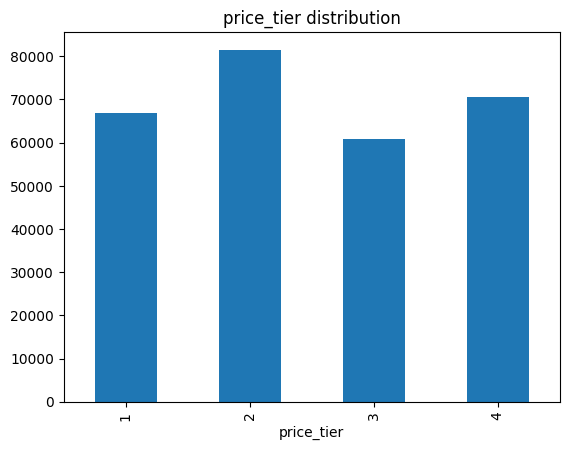

Majority-class macro F1: 0.1128361695767225


In [8]:
print(train[TARGET].value_counts().sort_index())
print(train[TARGET].value_counts(normalize=True).sort_index().round(3))
train[TARGET].value_counts().sort_index().plot(kind="bar", title="price_tier distribution"); plt.show()
maj = train[TARGET].mode()[0]
print("Majority-class macro F1:", f1_score(train[TARGET], [maj]*len(train), average="macro"))

                              train_%  test_%
borough                         76.66   75.12
score_value                     19.39   18.73
score_access                    19.39   18.73
score_onboarding                19.39   18.74
score_accuracy                  19.39   18.73
score_support                   19.39   18.73
last_review_date                19.39   18.73
reviews_per_month               19.39   18.73
score_condition                 19.39   18.73
first_review_date               19.39   18.73
score_overall                   19.39   18.73
zones                           17.31   18.42
utility_rooms                   10.69   10.59
workstations                     6.71    7.04
operator_active_years            0.22    0.19
operator_active_months           0.22    0.19
operator_has_avatar              0.22    0.19
operator_ref                     0.22    0.19
operator_id_verified             0.22    0.19
operator_platform_age_months     0.22    0.19
operator_platform_age_years      0

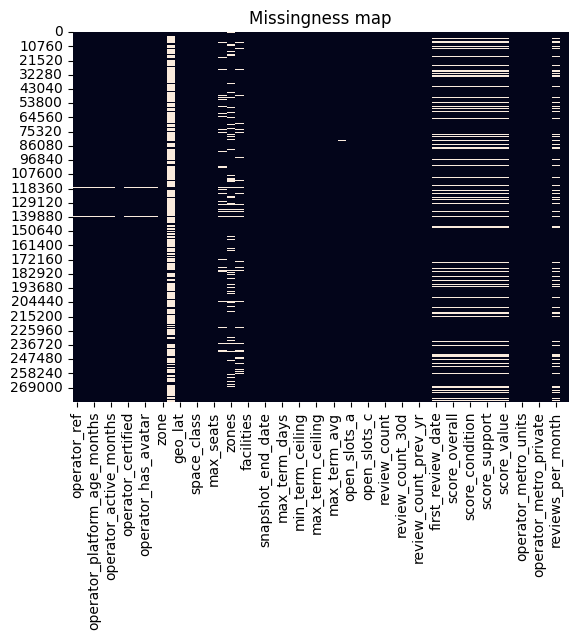

                              operator_ref  operator_platform_age_years  \
operator_ref                          1.00                         1.00   
operator_platform_age_years           1.00                         1.00   
operator_platform_age_months          1.00                         1.00   
operator_active_years                 1.00                         1.00   
operator_active_months                1.00                         1.00   
operator_certified                    1.00                         1.00   
operator_portfolio_size               1.00                         1.00   
operator_has_avatar                   1.00                         1.00   
operator_id_verified                  1.00                         1.00   
borough                              -0.05                        -0.05   
utility_rooms                         0.13                         0.13   
zones                                 0.10                         0.10   
workstations             

In [9]:
miss = pd.DataFrame({"train_%": train.isna().mean()*100, "test_%": test.isna().mean()*100})
print(miss[(miss > 0).any(axis=1)].sort_values("train_%", ascending=False).round(2))
sns.heatmap(train[feat].isna(), cbar=False); plt.title("Missingness map"); plt.show()

mc = train[feat].columns[train[feat].isna().any()]
print(train[mc].isna().corr().round(2))                       # do columns go missing together?
for c in mc[:8]:
    print(c, train.groupby(train[c].isna())[TARGET].value_counts(normalize=True).unstack().round(3))

In [10]:
X = train[feat]
print("exact duplicate rows:", X.duplicated().sum())
print("conflicting duplicates:", train[X.duplicated(keep=False)].groupby(feat, dropna=False)[TARGET].nunique().gt(1).sum())

def col(*names):  # helper: first matching column name
    return [c for c in train.columns if all(n in c for n in names)]
print("month cols:", col("months"))
for c in col("months"): print(c, "max =", train[c].max())
print("scores outside 0-10:", {c: ((train[c]<0)|(train[c]>10)).sum() for c in train.columns if c.startswith("score_")})

if {"operator_metro_units","operator_metro_whole","operator_metro_private","operator_metro_shared"} <= set(train.columns):
    s = train[["operator_metro_whole","operator_metro_private","operator_metro_shared"]].sum(axis=1)
    print("units != whole+private+shared:", (train["operator_metro_units"] != s).sum())
    print("metro units > portfolio:", (train["operator_metro_units"] > train["operator_portfolio_size"]).sum())
print("active > platform (years):", (train["operator_active_years"] > train["operator_platform_age_years"]).sum())
print(pd.crosstab(train["operator_class"], train["operator_certified"]))

print("negatives:", (train[num] < 0).sum()[lambda s: s>0].to_dict())
print("near-constant:", [c for c in feat if train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99])

exact duplicate rows: 1160
conflicting duplicates: 43
month cols: ['operator_platform_age_months', 'operator_active_months']
operator_platform_age_months max = 11.0
operator_active_months max = 11.0
scores outside 0-10: {'score_overall': np.int64(0), 'score_accuracy': np.int64(0), 'score_condition': np.int64(0), 'score_onboarding': np.int64(0), 'score_support': np.int64(0), 'score_access': np.int64(0), 'score_value': np.int64(0)}
units != whole+private+shared: 3428
metro units > portfolio: 1849
active > platform (years): 3
operator_certified        f      t
operator_class                    
independent_operator  63402  48485
managed_operator      26970  13416
unverified_operator   89863  37006
negatives: {'geo_lat': 22706, 'geo_lon': 232422}
near-constant: ['bookable']


                                 count      mean          std     min     25%  \
operator_platform_age_years   279142.0      6.79         4.19    0.00    3.00   
operator_platform_age_months  279142.0      5.45         3.49    0.00    2.00   
operator_active_years         279140.0      5.08         4.04    0.00    2.00   
operator_active_months        279140.0      5.30         3.48    0.00    2.00   
operator_portfolio_size       279142.0     49.47       332.75    0.00    1.00   
geo_lat                       279746.0     77.77        37.51   -4.82   68.04   
geo_lon                       279746.0    -35.14        57.17 -123.75  -76.56   
max_seats                     279746.0      3.63         2.28    1.00    2.00   
utility_rooms                 249847.0      1.36         0.81    0.50    1.00   
zones                         231332.0      1.66         1.09    0.00    1.00   
workstations                  260963.0      2.16         1.71    1.00    1.00   
min_term_days               

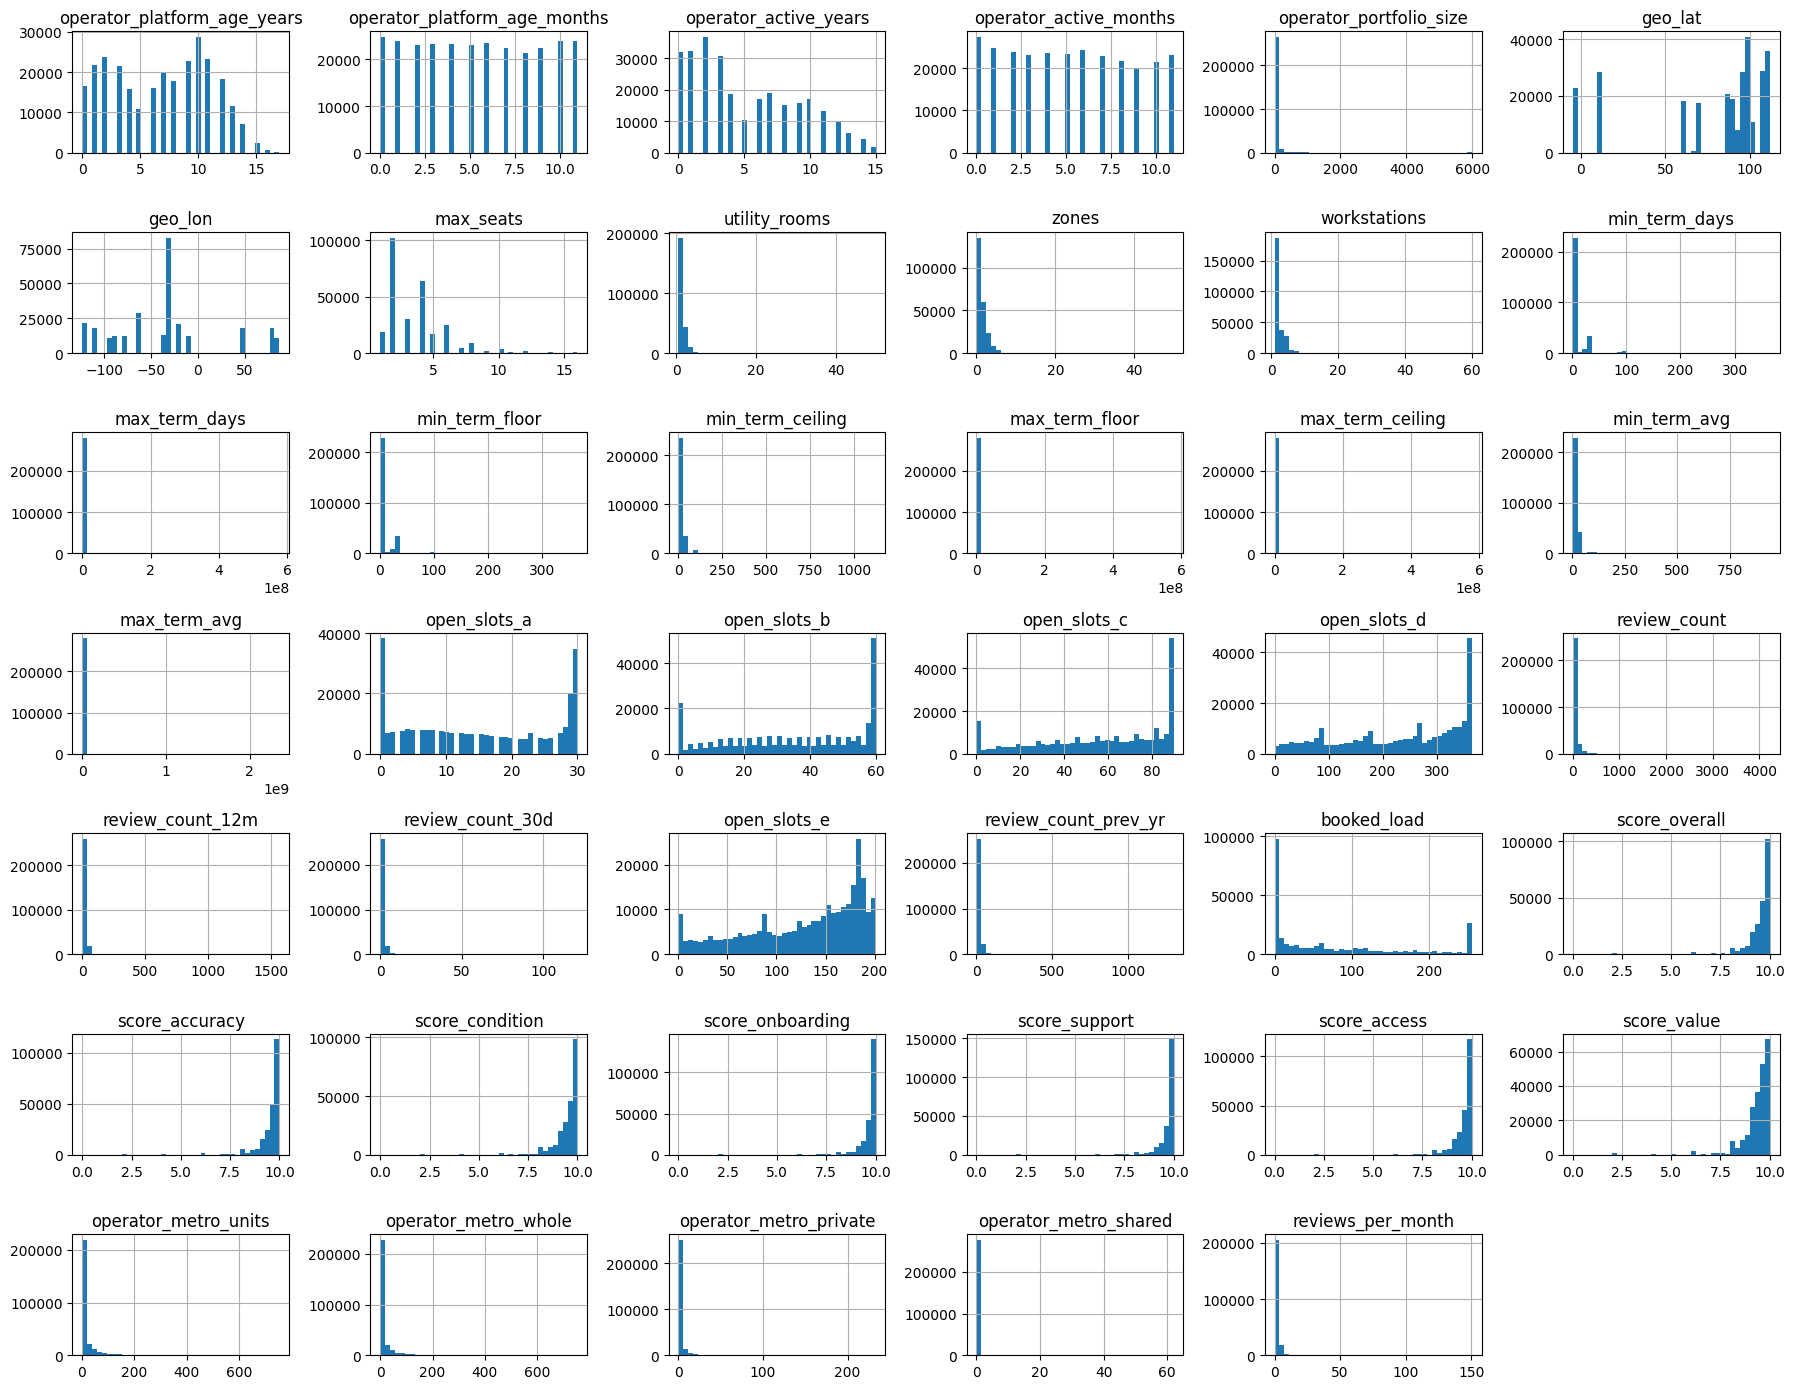

IQR outlier % per column:
 min_term_ceiling           20.63
min_term_avg               20.45
min_term_floor             18.98
min_term_days              18.98
geo_lat                    18.32
operator_metro_private     17.79
operator_metro_whole       16.07
operator_metro_units       14.35
operator_portfolio_size    14.22
review_count_30d           13.85
geo_lon                    10.38
review_count               10.17
review_count_prev_yr        9.92
review_count_12m            6.98
score_support               6.88
dtype: float64
skewed columns (|skew|>1): ['operator_portfolio_size', 'geo_lat', 'max_seats', 'utility_rooms', 'zones', 'workstations', 'min_term_days', 'max_term_days', 'min_term_floor', 'min_term_ceiling', 'max_term_floor', 'max_term_ceiling', 'min_term_avg', 'max_term_avg', 'review_count', 'review_count_12m', 'review_count_30d', 'review_count_prev_yr', 'score_overall', 'score_accuracy', 'score_condition', 'score_onboarding', 'score_support', 'score_access', 'score_value'

In [11]:
print(train[num].describe().T.assign(skew=train[num].skew()).round(2))
train[num].hist(bins=40, figsize=(18,14)); plt.tight_layout(); plt.show()
q1, q3 = train[num].quantile(.25), train[num].quantile(.75); iqr = q3 - q1
out = (((train[num] < q1-1.5*iqr) | (train[num] > q3+1.5*iqr)).mean()*100).round(2)
print("IQR outlier % per column:\n", out.sort_values(ascending=False).head(15))
print("skewed columns (|skew|>1):", train[num].skew()[lambda s: s.abs()>1].index.tolist())

In [12]:
for c in cat:
    print(f"\n{c}: {train[c].nunique()} unique")
    print(train[c].value_counts(normalize=True).head(8).round(3))
# operator overlap between train and test
print("test operators also in train:", test["operator_ref"].isin(train["operator_ref"]).mean().round(3))
print("listings per operator:\n", train["operator_ref"].value_counts().describe())


operator_ref: 41903 unique
operator_ref
Bessstu       0.005
Zianovath     0.004
Nalsto        0.004
Dessselra     0.004
Stianianlo    0.003
Klynfova      0.003
Sinnovara     0.003
Zelten        0.003
Name: proportion, dtype: float64

operator_class: 3 unique
operator_class
unverified_operator     0.456
independent_operator    0.400
managed_operator        0.144
Name: proportion, dtype: float64

operator_certified: 2 unique
operator_certified
f    0.646
t    0.354
Name: proportion, dtype: float64

operator_has_avatar: 2 unique
operator_has_avatar
t    0.958
f    0.042
Name: proportion, dtype: float64

operator_id_verified: 2 unique
operator_id_verified
t    0.986
f    0.014
Name: proportion, dtype: float64

zone: 1380 unique
zone
ZN-0923    0.039
ZN-0779    0.034
ZN-0948    0.031
ZN-0536    0.017
ZN-1039    0.013
ZN-0454    0.013
ZN-0812    0.011
ZN-0315    0.010
Name: proportion, dtype: float64

borough: 55 unique
borough
BRG-18    0.163
BRG-30    0.141
BRG-22    0.134
BRG-14    0.082

In [16]:
s = train.sample(20000, random_state=42)
print(s.shape)
print(s["price_tier"].value_counts(normalize=True).sort_index().round(3))

(20000, 60)
price_tier
1    0.235
2    0.293
3    0.216
4    0.256
Name: proportion, dtype: float64


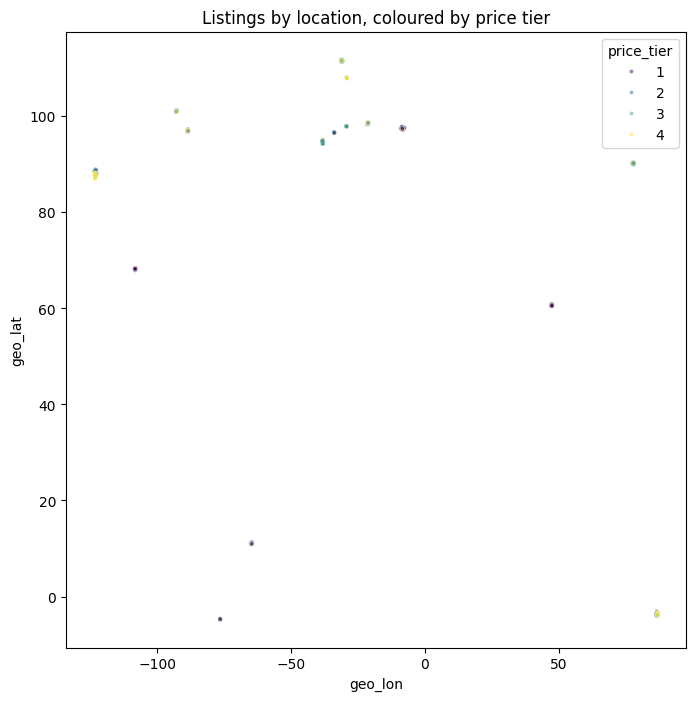

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 8))
sns.scatterplot(data=s, x="geo_lon", y="geo_lat", hue="price_tier",
                palette="viridis", s=8, alpha=0.5)
plt.title("Listings by location, coloured by price tier")
plt.show()

In [18]:
cat_cols = s.select_dtypes(exclude="number").columns
print(s[cat_cols].nunique().sort_values())
print(s["facilities"].head(3).tolist())

operator_has_avatar         2
operator_certified          2
operator_id_verified        2
bookable                    2
operator_class              3
access_type                 4
compliance_status           4
metro                      16
borough                    54
space_class                82
snapshot_start_date       323
snapshot_end_date         351
zone                     1039
last_review_date         1489
first_review_date        3608
operator_ref             8733
facilities              19435
dtype: int64
['["FCL-012", "FCL-104", "FCL-058", "FCL-085", "FCL-098", "FCL-138", "FCL-040", "FCL-139", "FCL-007", "FCL-141", "FCL-093", "FCL-005", "FCL-142", "FCL-136", "FCL-106", "FCL-056", "FCL-042", "FCL-143", "FCL-083", "FCL-118", "FCL-080", "FCL-014", "FCL-035", "FCL-090", "FCL-030", "FCL-099", "FCL-145", "FCL-087", "FCL-078", "FCL-020"]', '["FCL-071", "FCL-072", "FCL-093", "FCL-138", "FCL-137", "FCL-080", "FCL-055", "FCL-029", "FCL-056", "FCL-135", "FCL-132", "FCL-077", "FCL-139

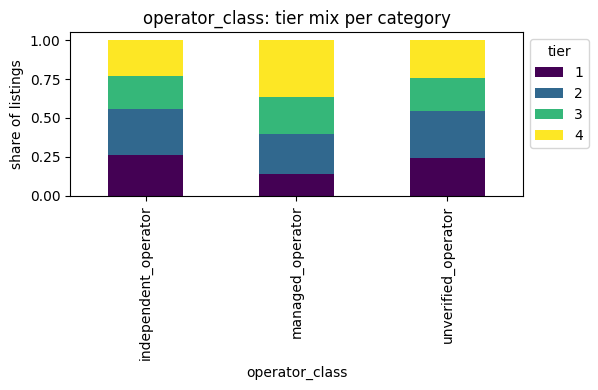

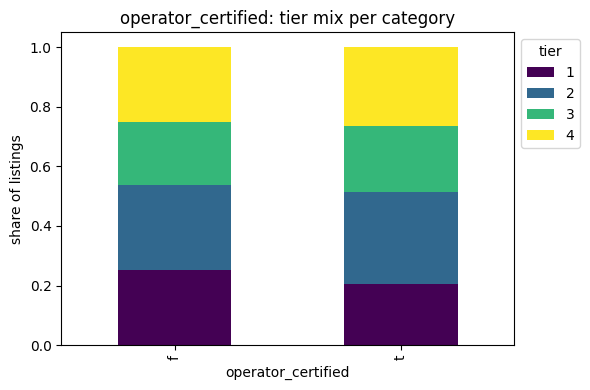

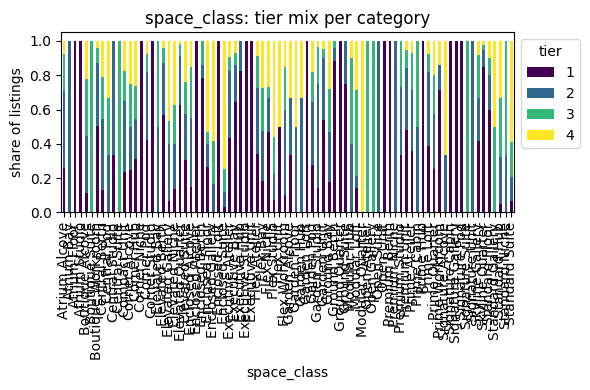

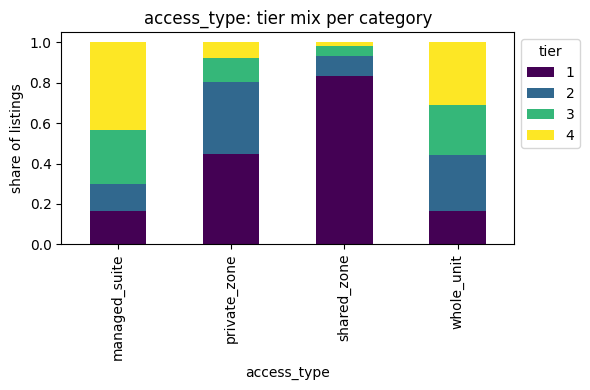

In [19]:
for c in ["operator_class", "operator_certified", "space_class", "access_type"]:
    pd.crosstab(s[c], s["price_tier"], normalize="index").plot(
        kind="bar", stacked=True, figsize=(6, 4), colormap="viridis")
    plt.title(c + ": tier mix per category")
    plt.ylabel("share of listings")
    plt.legend(title="tier", bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.show()

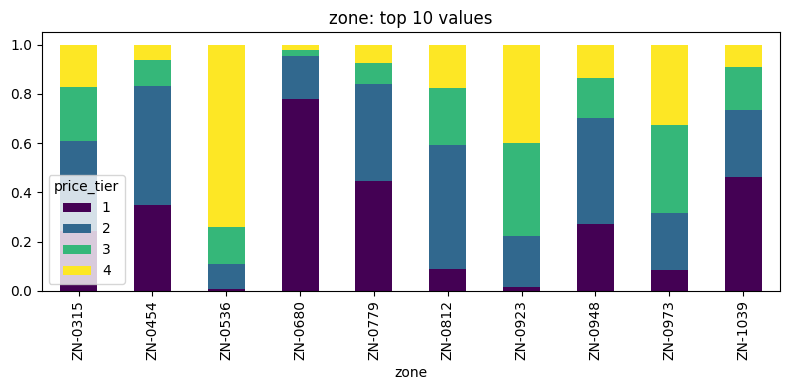

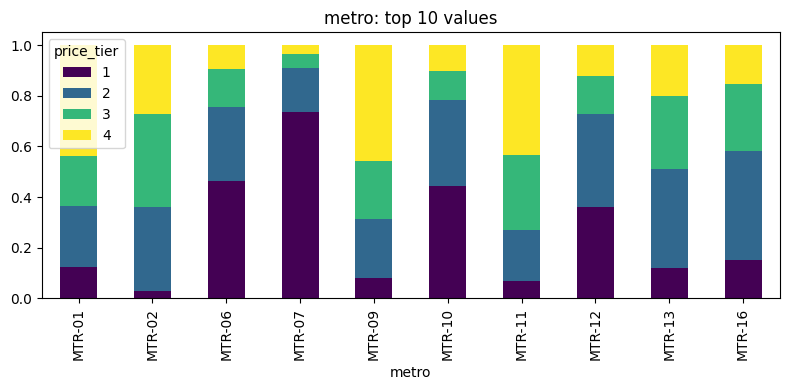

In [20]:
for c in ["zone", "metro"]:
    top = s[c].value_counts().head(10).index
    sub = s[s[c].isin(top)]
    pd.crosstab(sub[c], sub["price_tier"], normalize="index").plot(
        kind="bar", stacked=True, figsize=(8, 4), colormap="viridis")
    plt.title(c + ": top 10 values")
    plt.tight_layout()
    plt.show()

In [21]:
import lightgbm as lgb   # preinstalled on Kaggle; otherwise: pip install lightgbm
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import f1_score

drop_cols = ["space_id", "operator_ref", "price_tier",
             "snapshot_start_date", "snapshot_end_date",
             "first_review_date", "last_review_date"]
X = train.drop(columns=drop_cols)
y = train["price_tier"] - 1          # LightGBM expects classes 0..3, not 1..4

for c in X.select_dtypes(exclude="number"):
    X[c] = X[c].astype("category")   # tells LightGBM these are categories

In [22]:
def fit_and_score(tr_idx, va_idx):
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.1,
                           class_weight="balanced", random_state=42, n_jobs=-1)
    m.fit(X.iloc[tr_idx], y.iloc[tr_idx],
          eval_set=[(X.iloc[va_idx], y.iloc[va_idx])],
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
    pred = m.predict(X.iloc[va_idx])
    return f1_score(y.iloc[va_idx], pred, average="macro"), m

In [23]:
feat_cols = [c for c in train.columns if c not in ("space_id", "price_tier")]

dup_mask = train.duplicated(subset=feat_cols, keep=False)
d = train[dup_mask]
n_labels = d.groupby(feat_cols, dropna=False)["price_tier"].transform("nunique")
bad_idx = d.index[n_labels > 1]                 # duplicates with contradicting tiers

train_clean = train.drop(index=bad_idx).drop_duplicates(subset=feat_cols).reset_index(drop=True)
print(len(train), "->", len(train_clean))

279746 -> 278543


In [24]:
def add_features(d):
    d = d.copy()
    for c in ["snapshot_start_date", "snapshot_end_date", "first_review_date", "last_review_date"]:
        d[c] = pd.to_datetime(d[c], errors="coerce")
    d["snapshot_span_days"] = (d["snapshot_end_date"] - d["snapshot_start_date"]).dt.days
    d["days_since_first_review"] = (d["snapshot_end_date"] - d["first_review_date"]).dt.days
    d["days_since_last_review"] = (d["snapshot_end_date"] - d["last_review_date"]).dt.days
    d["snapshot_month"] = d["snapshot_start_date"].dt.month

    d["platform_tenure"] = d["operator_platform_age_years"] + d["operator_platform_age_months"] / 12
    d["active_tenure"] = d["operator_active_years"] + d["operator_active_months"] / 12
    d["has_reviews"] = d["score_overall"].notna().astype(int)
    sc = [c for c in d.columns if c.startswith("score_")]
    d["score_mean"] = d[sc].mean(axis=1)

    # flag impossible values instead of deleting rows
    d["metro_sum_mismatch"] = (d["operator_metro_units"] !=
        d["operator_metro_whole"] + d["operator_metro_private"] + d["operator_metro_shared"]).astype(int)
    d["metro_over_portfolio"] = (d["operator_metro_units"] > d["operator_portfolio_size"]).astype(int)

    return d.drop(columns=["space_id", "operator_ref", "bookable",
                           "snapshot_start_date", "snapshot_end_date",
                           "first_review_date", "last_review_date"], errors="ignore")

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

Xc = add_features(train_clean.drop(columns="price_tier"))
yc = train_clean["price_tier"] - 1
groups = train_clean["operator_ref"].fillna("missing")

cat_cols = Xc.select_dtypes(exclude="number").columns.tolist()

pre = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value",
                            unknown_value=-1, encoded_missing_value=-1), cat_cols)],
    remainder="passthrough")        # numeric columns pass through untouched

pipe = Pipeline([
    ("pre", pre),
    ("clf", lgb.LGBMClassifier(class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1)),
])

In [26]:
import json, joblib, pandas as pd
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import randint, uniform, loguniform

OUT = Path("/kaggle/working")

sub = Xc.sample(60000, random_state=42).index
Xs, ys, gs = Xc.loc[sub], yc.loc[sub], groups.loc[sub]

param_dist = {
    "clf__n_estimators":      randint(200, 800),
    "clf__learning_rate":     loguniform(0.02, 0.2),
    "clf__num_leaves":        randint(31, 200),
    "clf__min_child_samples": randint(20, 200),
    "clf__subsample":         uniform(0.6, 0.4),
    "clf__subsample_freq":    [1],
    "clf__colsample_bytree":  uniform(0.5, 0.5),
    "clf__reg_lambda":        loguniform(0.01, 10),
}

search = RandomizedSearchCV(pipe, param_dist, n_iter=15, cv=GroupKFold(3),
                            scoring="f1_macro", random_state=42, n_jobs=1, verbose=2)
search.fit(Xs, ys, groups=gs)

print("Best macro F1:", round(search.best_score_, 4))
print(search.best_params_)

# save everything worth keeping
joblib.dump(search.best_estimator_, OUT / "best_model.joblib")      # full pipeline, fitted on the 60k sample
pd.DataFrame(search.cv_results_).to_csv(OUT / "search_results.csv", index=False)
json.dump({"f1_macro": float(search.best_score_),
           "params": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}},
          open(OUT / "best_params.json", "w"), indent=2)

# refit the winning settings on all the data and save that too
final = clone(pipe).set_params(**search.best_params_).fit(Xc, yc)
joblib.dump(final, OUT / "final_pipe.joblib")

Fitting 3 folds for each of 15 candidates, totalling 45 fits


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END clf__colsample_bytree=0.6872700594236812, clf__learning_rate=0.1785436060870726, clf__min_child_samples=126, clf__n_estimators=271, clf__num_leaves=51, clf__reg_lambda=0.02938027938703535, clf__subsample=0.662397808134481, clf__subsample_freq=1; total time=   9.4s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END clf__colsample_bytree=0.6872700594236812, clf__learning_rate=0.1785436060870726, clf__min_child_samples=126, clf__n_estimators=271, clf__num_leaves=51, clf__reg_lambda=0.02938027938703535, clf__subsample=0.662397808134481, clf__subsample_freq=1; total time=   9.5s


...

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END clf__colsample_bytree=0.9436063712881633, clf__learning_rate=0.05932597997400133, clf__min_child_samples=120, clf__n_estimators=661, clf__num_leaves=161, clf__reg_lambda=1.9158219548093167, clf__subsample=0.8245108790277985, clf__subsample_freq=1; total time=  48.1s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END clf__colsample_bytree=0.9436063712881633, clf__learning_rate=0.05932597997400133, clf__min_child_samples=120, clf__n_estimators=661, clf__num_leaves=161, clf__reg_lambda=1.9158219548093167, clf__subsample=0.8245108790277985, clf__subsample_freq=1; total time=  50.4s
Best macro F1: 0.6694
{'clf__colsample_bytree': np.float64(0.7247253370691017), 'clf__learning_rate': np.float64(0.024913807939754118), 'clf__min_child_samples': 170, 'clf__n_estimators': 773, 'clf__num_leaves': 67, 'clf__reg_lambda': np.float64(1.5446089075047076), 'clf__subsample': np.float64(0.8550229885420852), 'clf__subsample_freq': 1}


['/kaggle/working/final_pipe.joblib']

In [28]:
sample = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv")
id_col, tgt_col = sample.columns[:2]

Xte = add_features(test)[Xc.columns]        # same feature function used to build Xc, same column order
pred = final.predict(Xte) + 1                # shift 0..3 back to tiers 1..4

submission = pd.DataFrame({id_col: test["space_id"].values, tgt_col: pred})
assert len(submission) == len(sample) and set(submission[id_col]) == set(sample[id_col])

submission.to_csv("/kaggle/working/submission.csv", index=False)
print(submission.shape)
print(submission[tgt_col].value_counts(normalize=True).sort_index().round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


(114538, 2)
price_tier
1    0.252
2    0.302
3    0.217
4    0.228
Name: proportion, dtype: float64


In [29]:
best = {
    "clf__colsample_bytree": 0.7247253370691017,
    "clf__learning_rate": 0.024913807939754118,
    "clf__min_child_samples": 170,
    "clf__n_estimators": 773,
    "clf__num_leaves": 67,
    "clf__reg_lambda": 1.5446089075047076,
    "clf__subsample": 0.8550229885420852,
    "clf__subsample_freq": 1,
}
final = clone(pipe).set_params(**best).fit(Xc, yc)